# 궤적 매칭 네 모드

**이 노트북에서 할 일**

1. 01절의 기준 궤적을 다시 만들고, 궤적 맞춰 보기 모드 넷으로 평가 함수를 하나씩 만듭니다.
2. 차례를 바꾼 궤적, 요청이 빠지거나 더해진 궤적, 검색을 세 번 한 궤적을 네 모드로 견줍니다.
3. 인자만 다른 궤적으로 인자 비교 방식 하나만 바꿔 보고, 도구별 덮어쓰기도 봅니다.

**준비물** — 이 노트북은 모델을 부르지 않습니다.
모델 요청은 0번이고, API 키 없이 실행합니다.
예상 비용도 0달러입니다.
궤적은 모두 코드로 적은 메시지 목록이라, 다시 실행해도 같은 값이 나와야 합니다.

읽는 파일은 같은 폴더의 도구 파일 `eval_tools.py` 하나이고, 쓰는 파일은 없습니다.
걸린 시간은 재지 않았습니다.

**기준 버전** — 첫 셀에서 패키지 둘을 설치합니다.
판은 agentevals 0.0.9와 langchain 1.4.0입니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~4절을 읽습니다.
네 모드를 만들고, 차례와 빠진 요청·더한 요청을 모드마다 어떻게 보는지 다루는 자리입니다.
5~7절은 짝짓기와 인자 비교를 궤적을 바꿔 가며 견주는 실습이고, 실습 시간에 실행합니다.

실습 폴더 `labs/part6/ch29-agent-evaluation`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 맨 위 초록 상자 둘은 기준 궤적의 도구 요청 search_documents와 check_source, 그리고 실제 궤적의 도구 요청입니다. 두 상자에서 아래 칸 둘로 화살표가 갑니다. 왼쪽 칸 메시지를 하나씩 견줌에는 파란 상자 strict, 메시지 수와 차례, 도구 요청이 모두 같아야 참이 있습니다. 오른쪽 칸 도구 요청만 모아 짝지음에는 파란 상자 셋이 위아래로 놓입니다. unordered 두 쪽 요청이 모두 짝을 찾으면 참, subset 실제 요청이 모두 짝을 찾으면 참, superset 기준 요청이 모두 짝을 찾으면 참인 그림](attachment:02-1-네-모드가-보는-것.png)

위에서 아래로 읽습니다.
맨 위 초록 상자 둘은 노트북 2절의 기준 궤적과, 3~5절에서 코드로 적은 실제 궤적의 도구 요청입니다.
아래 칸 둘의 파란 상자 넷은 2절에서 모드마다 만든 평가 함수이고, 상자 안 글은 참이 되는 조건입니다.
짝을 짓는 칸의 세 상자는 서로 다른 모드라 화살표 없이 위아래로 두었습니다.
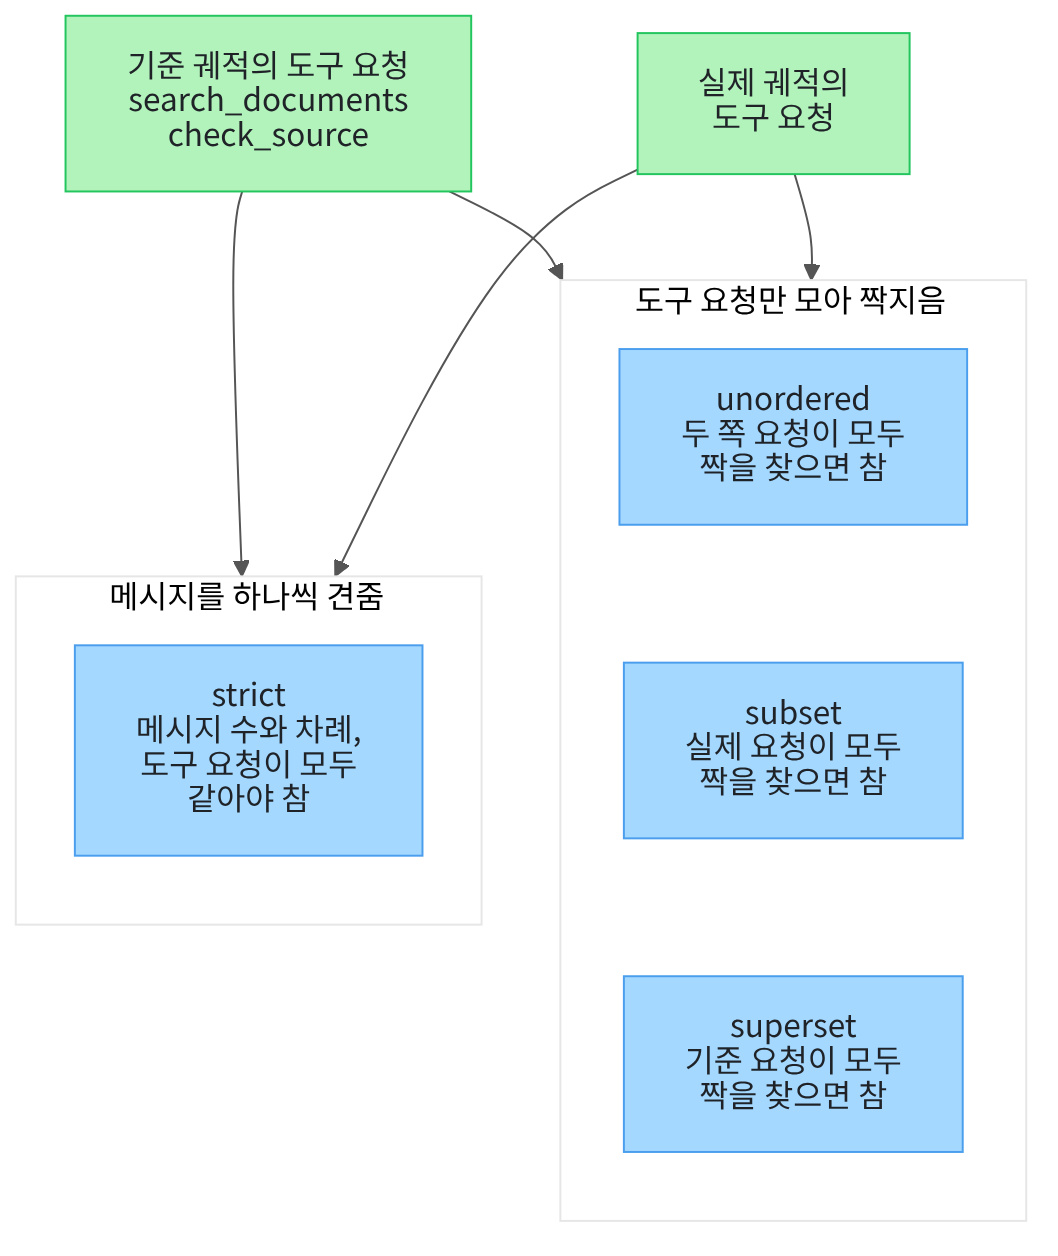

## 1. 준비

01절에서는 궤적 맞춰 보기의 모드 `strict` 하나로 궤적을 평가했습니다.
이 절은 모드 셋을 더 보고, 네 모드가 같은 궤적을 어떻게 달리 판정하는지 견줍니다.
뜻과 구성은 본문 「핵심 개념」에서 풉니다.

첫 셀은 패키지 둘을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "agentevals==0.0.9" "langchain==1.4.0"
from importlib.metadata import version

print("agentevals:", version("agentevals"))
print("langchain:", version("langchain"))

Note: you may need to restart the kernel to use updated packages.
agentevals: 0.0.9
langchain: 1.4.0


**결과 읽기** — 출력 줄 `agentevals: 0.0.9`와 `langchain: 1.4.0`이 보입니다.
둘 다 실습 폴더 잠금과 같은 판이고, 01절과 같은 패키지입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
함수 `create_trajectory_match_evaluator`는 01절에서 본 것처럼 모드 이름을 받아 평가 함수를 만들어 내놓습니다.
메시지 클래스 셋은 3절에서 궤적 하나를 손으로 만들 때 씁니다.

In [2]:
# 궤적을 맞춰 보는 평가 함수를 만드는 함수와, 메시지 클래스 셋(Ch 13 04절·Ch 19 05절)을 가져옵니다
from agentevals.trajectory.match import create_trajectory_match_evaluator
from langchain.messages import AIMessage, HumanMessage, ToolMessage
# 01절에서 배운 함수 셋은 도구 파일에서 가져옵니다
from eval_tools import called_tool_names, make_trajectory, trajectory_pass

print("도구 파일에서 가져온 함수:", "called_tool_names, make_trajectory, trajectory_pass")

도구 파일에서 가져온 함수: called_tool_names, make_trajectory, trajectory_pass


**결과 읽기** — 출력 줄 `도구 파일에서 가져온 함수: called_tool_names, make_trajectory, trajectory_pass`가 보입니다.
앞에서 배운 함수는 `eval_tools.py`에 모아 두었습니다.
파일을 열면 코드를 볼 수 있습니다.

노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
교재 출력을 만든 실행 도구는 이 폴더를 따로 알려 주어, 다른 자리에서 시작해도 가져오기가 되었습니다.

세 함수는 01절 노트북에서 처음 적은 함수이고, 이 절부터 도구 파일에서 가져옵니다.
도구 파일에는 01절 셀의 주석과 본문을 글자 그대로 옮겼고, 인자도 01절과 같습니다.
함수 `make_trajectory(question, calls, results, answer)`는 질문·도구 요청 목록·결과 글·답 글로 궤적을 만듭니다.
함수 `called_tool_names(messages)`는 도구 차례를, `trajectory_pass(messages, reference, evaluator)`는 칸 `score`를 내놓습니다.

## 2. 기준 궤적과 네 모드의 평가 함수

01절에서 본 것처럼, 이 챕터는 에이전트가 질문에서 최종 답까지 밟은 단계의 차례를 궤적이라고 부릅니다.
이 절도 에이전트를 실행하지 않고, 질문에서 답까지의 메시지 목록을 코드로 적어 궤적으로 씁니다.
다음 셀은 01절과 같은 질문·기준 답·결과 글을 정합니다.
4절에서 쓸 예약 도구 `reserve_book`의 결과 글도 하나 더합니다.
도구 셋의 함수는 만들지 않고, 결과 글만 정해 둡니다.

In [3]:
# 질문과 기준 답, 도구마다 돌아올 결과 글을 정합니다(01절과 같은 글에 예약 도구의 글 하나를 더함)
question = "일반 도서는 며칠 동안 빌릴 수 있나요?"
reference_answer = "일반 도서는 14일 동안 빌릴 수 있습니다."
tool_results = {
    "search_documents": "[LIB-001] 일반 도서는 14일 동안 대출할 수 있습니다. 예약자가 없으면 한 번 연장할 수 있습니다.",
    "check_source": "LIB-001 문서가 있습니다. 제목: 도서 대출 기간",
    "reserve_book": "B-102 도서를 예약했습니다.",
}
print("질문:", question)
print("기준 답:", reference_answer)
print("결과 글을 정한 도구:", list(tool_results))

질문: 일반 도서는 며칠 동안 빌릴 수 있나요?
기준 답: 일반 도서는 14일 동안 빌릴 수 있습니다.
결과 글을 정한 도구: ['search_documents', 'check_source', 'reserve_book']


**결과 읽기** — 출력 줄 `기준 답: 일반 도서는 14일 동안 빌릴 수 있습니다.`가 보입니다.
라벨 `결과 글을 정한 도구:` 뒤에는 `'search_documents'`·`'check_source'`·`'reserve_book'`이 있습니다.

도구 `reserve_book`은 도서를 예약하는 도구로, Ch 19 06절에서 본 쓰기 도구에 해당합니다.
질문은 대출 기간만 물었으므로, 예약은 누구도 부탁하지 않은 일입니다.

다음 셀은 01절과 같은 도구 요청 둘로 기준 궤적을 만듭니다.
기준 궤적은 문서를 한 번 검색하고, 찾은 문서가 있는지 한 번 확인한 뒤 답하는 차례입니다.

In [4]:
# 01절과 같은 도구 요청 둘로 기준 궤적을 만들고, 도구 차례와 메시지 수를 봅니다
search_args = {"query": "도서 대출 기간"}
source_args = {"doc_id": "LIB-001"}
reference_calls = [
    {"name": "search_documents", "args": search_args, "id": "call_1", "type": "tool_call"},
    {"name": "check_source", "args": source_args, "id": "call_2", "type": "tool_call"},
]
reference = make_trajectory(question, reference_calls, tool_results, reference_answer)
reference_names = called_tool_names(reference)
print("기준 궤적의 도구 차례:", reference_names)
print("메시지 수:", len(reference))

기준 궤적의 도구 차례: ['search_documents', 'check_source']
메시지 수: 6


**결과 읽기** — 출력 줄 `기준 궤적의 도구 차례: ['search_documents', 'check_source']`와 `메시지 수: 6`이 보입니다.
01절의 기준 궤적과 같은 요청이고, 메시지 수도 같습니다.
목록 `reference_names`는 5절에서 다른 궤적의 도구 이름과 견줄 때 다시 씁니다.

다음 셀은 모드 넷마다 평가 함수를 하나씩 만듭니다.
모드 이름 넷을 목록에 담고, 반복문으로 인자 `trajectory_match_mode`에 하나씩 넣습니다.
만든 평가 함수는 모드 이름을 키로 한 딕셔너리에 모읍니다.

In [5]:
# 모드 넷마다 궤적을 맞춰 보는 평가 함수를 하나씩 만들어, 모드 이름을 키로 딕셔너리에 모읍니다
modes = ["strict", "unordered", "subset", "superset"]
evaluators = {}
for mode in modes:
    evaluators[mode] = create_trajectory_match_evaluator(trajectory_match_mode=mode)
print("평가 함수를 만든 모드:", list(evaluators))

평가 함수를 만든 모드: ['strict', 'unordered', 'subset', 'superset']


**결과 읽기** — 출력 줄 `평가 함수를 만든 모드: ['strict', 'unordered', 'subset', 'superset']`이 보입니다.
딕셔너리 `evaluators`에서 모드 이름으로 평가 함수를 꺼내 씁니다.
예를 들어 `evaluators["subset"]`은 모드 `subset`으로 만든 평가 함수입니다.

다음 셀은 기준 궤적을 자기 자신과 견줘, 모드마다 결과 딕셔너리의 칸 둘을 봅니다.
칸 `key`는 결과의 이름이고, 칸 `score`는 판정입니다.

In [6]:
# 기준 궤적을 자기 자신과 견줘, 모드마다 결과 딕셔너리의 칸 key와 score를 봅니다
for mode in evaluators:
    result = evaluators[mode](outputs=reference, reference_outputs=reference)
    print(mode, "|", result["key"], "|", result["score"])

strict | trajectory_strict_match | True
unordered | trajectory_unordered_match | True
subset | trajectory_subset_match | True
superset | trajectory_superset_match | True


**결과 읽기** — 네 줄 모두 칸 `score`가 `True`입니다.
줄 `unordered | trajectory_unordered_match | True`처럼, 칸 `key`에는 모드 이름이 들어갑니다.
같은 궤적끼리는 네 모드 모두 참이라, 자기 자신과 견준 판정으로는 모드를 가를 수 없습니다.

모드 넷은 기준 궤적과 무엇이 같아야 참인지가 다릅니다.
모드 `strict`는 01절에서 본 것처럼 메시지를 하나씩 견줍니다.
나머지 셋은 궤적 전체에서 도구 요청만 모아, 기준 궤적의 도구 요청과 하나씩 짝을 짓습니다.
이름이 같고 인자가 맞는 요청끼리 짝이 되며, 이렇게 짝을 짓는 일을 짝짓기라고 부르겠습니다.
어느 쪽 요청이 모두 짝을 찾아야 하는지가 모드마다 다르고, 3~5절에서 하나씩 봅니다.

다음 셀은 한 궤적을 네 모드로 한꺼번에 견주는 함수를 정의합니다.
평가 함수마다 01절 함수 `trajectory_pass`로 칸 `score`만 꺼내, 모드 이름을 키로 모읍니다.

In [7]:
# 한 궤적을 네 모드의 평가 함수로 모두 견줘, 모드 이름을 키로 한 점수 딕셔너리로 내놓습니다
def four_modes(messages, reference, evaluators):
    row = {}
    for mode in evaluators:
        # 01절 함수 trajectory_pass가 결과 딕셔너리에서 칸 score만 꺼냅니다
        row[mode] = trajectory_pass(messages, reference, evaluators[mode])
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.
내놓는 딕셔너리는 키가 모드 이름 넷이고, 값은 참·거짓 값입니다.

## 3. 차례를 바꾼 궤적: 모드 strict와 unordered

먼저 볼 모드는 `unordered`입니다.
모드 `unordered`는 기준 요청과 실제 요청이 모두 서로 짝을 찾으면 참을 냅니다.
짝을 지을 때 차례는 보지 않습니다.

다음 셀은 01절의 차례 바꿈과 같은 궤적을 만듭니다.
출처 확인을 먼저 하고 검색을 뒤에 하며, 답은 기준과 같은 글입니다.

In [8]:
# 출처 확인을 먼저 하고 검색을 뒤에 하는, 차례를 바꾼 궤적을 만듭니다(01절의 차례 바꿈과 같은 요청)
reversed_calls = [
    {"name": "check_source", "args": source_args, "id": "call_1", "type": "tool_call"},
    {"name": "search_documents", "args": search_args, "id": "call_2", "type": "tool_call"},
]
reversed_order = make_trajectory(question, reversed_calls, tool_results, reference_answer)
print("도구 차례:", called_tool_names(reversed_order))

도구 차례: ['check_source', 'search_documents']


**결과 읽기** — 출력 줄 `도구 차례: ['check_source', 'search_documents']`가 보입니다.
도구 둘은 기준 궤적과 같고, 차례만 거꾸로입니다.

다음 셀은 이 궤적을 네 모드로 견줍니다.
실행 전에 예상해 봅니다.
차례를 보는 모드와 보지 않는 모드의 판정이 갈릴까요?
마지막 두 줄의 `assert`는 모드에 따라 갈린 값이 다시 실행해도 같은지 확인합니다.

In [9]:
# 차례를 바꾼 궤적을 네 모드로 견줍니다
reversed_row = four_modes(reversed_order, reference, evaluators)
print("차례 바꿈:", reversed_row)
# 모드에 따라 갈린 두 값이 다시 실행해도 같은지 assert로 확인합니다
assert not reversed_row["strict"]
assert reversed_row["unordered"]

차례 바꿈: {'strict': False, 'unordered': True, 'subset': True, 'superset': True}


**결과 읽기** — 출력 줄 `차례 바꿈: {'strict': False, 'unordered': True, 'subset': True, 'superset': True}`가 보입니다.
모드 `strict`만 거짓이고, 나머지 셋은 참입니다.
두 줄의 `assert`도 오류 없이 지나갔습니다.

모드 `strict`는 메시지를 하나씩 견주므로, 첫 모델 응답의 도구 요청부터 기준과 달랐습니다.
나머지 셋은 도구 요청을 모아 짝을 지었고, 기준 요청 둘과 실제 요청 둘이 모두 짝을 찾았습니다.
검색과 출처 확인의 차례가 상관없는 일이라면, 모드 `unordered`로 맞춰 볼 수 있습니다.

다음 셀은 모델 응답 하나가 검색과 출처 확인을 함께 요청한 궤적을 손으로 만듭니다.
Ch 19 05절에서 본 것처럼, 모델은 한 응답에 도구 호출 요청을 여럿 담을 수 있습니다.
Ch 20 01절처럼 모델 없이, `AIMessage`의 인자 `tool_calls`에 요청 둘을 함께 넣습니다.

In [10]:
# 모델 응답 하나가 검색과 출처 확인을 함께 요청한 궤적을 손으로 만듭니다(한 응답에 도구 호출 요청 둘)
both_calls = AIMessage(content="", tool_calls=reference_calls)
two_in_one = [HumanMessage(content=question), both_calls]
# 도구 메시지 둘은 요청과 같은 호출 ID를 달고 차례대로 붙입니다
two_in_one.append(ToolMessage(content=tool_results["search_documents"], tool_call_id="call_1"))
two_in_one.append(ToolMessage(content=tool_results["check_source"], tool_call_id="call_2"))
two_in_one.append(AIMessage(content=reference_answer))
print("도구 차례:", called_tool_names(two_in_one), "| 메시지 수:", len(two_in_one))

도구 차례: ['search_documents', 'check_source'] | 메시지 수: 5


**결과 읽기** — 출력 줄 `도구 차례: ['search_documents', 'check_source'] | 메시지 수: 5`가 보입니다.
도구 차례는 기준 궤적과 같지만, 메시지는 기준보다 하나 적은 다섯 개입니다.
요청 둘을 한 응답에 담아, 모델 응답이 하나 줄었기 때문입니다.

다음 셀은 이 궤적을 네 모드로 견줍니다.

In [11]:
# 한 응답에 요청 둘인 궤적을 네 모드로 견줍니다
two_row = four_modes(two_in_one, reference, evaluators)
print("한 응답에 요청 둘:", two_row)

한 응답에 요청 둘: {'strict': False, 'unordered': True, 'subset': True, 'superset': True}


**결과 읽기** — 출력 줄 `한 응답에 요청 둘: {'strict': False, 'unordered': True, 'subset': True, 'superset': True}`가 보입니다.
도구 차례가 기준과 같은데도 모드 `strict`는 거짓을 냈습니다.

모드 `strict`는 메시지 수부터 견주고, 이 궤적은 메시지가 다섯이라 기준의 여섯과 다릅니다.
나머지 셋은 메시지가 몇 개인지 보지 않고, 궤적 전체에서 모은 도구 요청만 짝지었습니다.
설치판 agentevals 0.0.9 소스 `trajectory/strict.py` 34행이 메시지 수를 먼저 견주는 줄입니다.
LangChain 문서 표는 모드 `unordered`도 메시지 구조가 같아야 한다고 적지만, 설치판 출력은 참이었습니다.

## 4. 빠진 요청과 더한 요청: 모드 subset과 superset

모드 `subset`은 실제 요청이 모두 기준 요청과 짝을 찾으면 참을 냅니다.
기준 요청이 남는 것, 곧 기준에 있는 요청을 빠뜨린 것은 봐줍니다.
모드 `superset`은 반대로 기준 요청이 모두 실제 요청과 짝을 찾으면 참을 냅니다.
실제 요청이 남는 것, 곧 기준에 없는 요청을 더한 것은 봐줍니다.

다음 셀은 검색만 하고 출처 확인은 하지 않은 궤적을 만듭니다.

In [12]:
# 검색만 하고 출처 확인은 하지 않은 궤적을 만듭니다(답은 기준과 같은 글)
short_calls = [reference_calls[0]]
short = make_trajectory(question, short_calls, tool_results, reference_answer)
print("도구 차례:", called_tool_names(short))

도구 차례: ['search_documents']


**결과 읽기** — 출력 줄 `도구 차례: ['search_documents']`가 보입니다.
기준 요청 둘 가운데 출처 확인이 빠졌습니다.

다음 셀은 이 궤적을 네 모드로 견줍니다.
실행 전에 예상해 봅니다.
빠진 요청을 봐주는 모드는 어느 쪽일까요?

In [13]:
# 검색만 한 궤적을 네 모드로 견줍니다
short_row = four_modes(short, reference, evaluators)
print("검색만:", short_row)
# 모드에 따라 갈린 두 값을 assert로 확인합니다
assert short_row["subset"]
assert not short_row["superset"]

검색만: {'strict': False, 'unordered': False, 'subset': True, 'superset': False}


**결과 읽기** — 출력 줄 `검색만: {'strict': False, 'unordered': False, 'subset': True, 'superset': False}`가 보입니다.
네 모드 가운데 모드 `subset`만 참입니다.

실제의 검색 요청은 기준 요청과 짝을 찾았고, 기준의 출처 확인 요청은 짝 없이 남았습니다.
모드 `subset`은 실제 요청만 모두 짝을 찾으면 되므로 참입니다.
모드 `superset`과 `unordered`는 기준 요청이 모두 짝을 찾아야 해서 거짓입니다.
그래서 모드 `subset`이 참이어도, 필요한 도구를 다 불렀다는 뜻은 아닙니다.

다음 셀은 반대로, 기준 요청 둘 뒤에 도서 예약 요청을 하나 더한 궤적을 만듭니다.

In [14]:
# 검색·출처 확인 뒤에, 묻지 않은 도서 예약까지 요청한 궤적을 만듭니다(답은 기준과 같은 글)
reserve_call = {
    "name": "reserve_book",
    "args": {"book_id": "B-102"},
    "id": "call_3",
    "type": "tool_call",
}
extra_calls = [reference_calls[0], reference_calls[1], reserve_call]
extra = make_trajectory(question, extra_calls, tool_results, reference_answer)
print("도구 차례:", called_tool_names(extra))

도구 차례: ['search_documents', 'check_source', 'reserve_book']


**결과 읽기** — 출력 줄 `도구 차례: ['search_documents', 'check_source', 'reserve_book']`가 보입니다.
기준 요청 둘 뒤에, 질문과 상관없는 예약 요청이 하나 붙었습니다.

다음 셀은 이 궤적을 네 모드로 견줍니다.
실행 전에 예상해 봅니다.
더한 요청을 봐주는 모드는 어느 쪽일까요?

In [15]:
# 예약을 더한 궤적을 네 모드로 견줍니다
extra_row = four_modes(extra, reference, evaluators)
print("예약을 더함:", extra_row)
# 검색만 한 궤적과 반대로 갈린 두 값을 assert로 확인합니다
assert not extra_row["subset"]
assert extra_row["superset"]

예약을 더함: {'strict': False, 'unordered': False, 'subset': False, 'superset': True}


**결과 읽기** — 출력 줄 `예약을 더함: {'strict': False, 'unordered': False, 'subset': False, 'superset': True}`가 보입니다.
이번에는 모드 `superset`만 참이고, 검색만 한 궤적과 반대입니다.

기준 요청 둘은 모두 짝을 찾았고, 실제의 예약 요청이 짝 없이 남았습니다.
모드 `superset`은 기준 요청만 모두 짝을 찾으면 되므로, 묻지 않은 예약을 한 궤적도 참으로 봤습니다.
예약처럼 무언가를 바꾸는 쓰기 도구를 막아야 한다면, 모드 `superset`만으로는 잡지 못합니다.
모드 `subset`은 이 예약 요청을 거짓으로 잡았습니다.

## 5. 짝짓기는 횟수까지 셉니다

다음 셀은 01절처럼 같은 검색어로 검색을 세 번 한 뒤 출처를 확인하는 궤적을 만듭니다.
도구 이름만 보면 두 가지 모두 기준에 있는 도구입니다.

In [16]:
# 01절처럼 같은 검색어로 검색을 세 번 한 뒤 출처를 확인하는 궤적을 만듭니다(답은 기준과 같은 글)
wasteful_calls = [
    {"name": "search_documents", "args": search_args, "id": "call_1", "type": "tool_call"},
    {"name": "search_documents", "args": search_args, "id": "call_2", "type": "tool_call"},
    {"name": "search_documents", "args": search_args, "id": "call_3", "type": "tool_call"},
    {"name": "check_source", "args": source_args, "id": "call_4", "type": "tool_call"},
]
wasteful = make_trajectory(question, wasteful_calls, tool_results, reference_answer)
wasteful_names = called_tool_names(wasteful)
print("도구 차례:", wasteful_names)

도구 차례: ['search_documents', 'search_documents', 'search_documents', 'check_source']


**결과 읽기** — 라벨 `도구 차례:` 뒤에 `'search_documents'`가 셋, `'check_source'`가 하나 있습니다.
01절에서 궤적 평가만 거짓을 낸 검색 세 번 궤적과 같은 요청입니다.

다음 셀은 이 궤적을 네 모드로 견줍니다.
실행 전에 예상해 봅니다.
실제 요청의 이름이 모두 기준에 있으니, 모드 `subset`은 참이 될까요?

In [17]:
# 검색 세 번 궤적을 네 모드로 견줍니다
wasteful_row = four_modes(wasteful, reference, evaluators)
print("검색 세 번:", wasteful_row)
# 도구 이름은 모두 기준에 있는데도 갈린 두 값을 assert로 확인합니다
assert not wasteful_row["subset"]
assert wasteful_row["superset"]

검색 세 번: {'strict': False, 'unordered': False, 'subset': False, 'superset': True}


**결과 읽기** — 출력 줄 `검색 세 번: {'strict': False, 'unordered': False, 'subset': False, 'superset': True}`가 보입니다.
모드 `subset`도 거짓이고, 모드 `superset`만 참입니다.

도구 이름이 모두 기준에 있어도 모드 `subset`은 참을 내지 않았습니다.
다음 셀들에서 까닭을 이름과 횟수로 나눠 봅니다.
먼저 도구 이름이 기준에 있는지만 보고, 검색 요청이 몇 번인지 셉니다.
목록의 `count`는 괄호 안의 값이 목록에 몇 번 들어 있는지 세어 내놓습니다.

In [18]:
# 검색 세 번 궤적의 도구 이름이 기준 도구 차례에 있는 이름인지만 하나씩 봅니다(횟수는 세지 않음)
for name in wasteful_names:
    print(name, "| 기준에 있는 이름인가:", name in reference_names)
# 목록의 count는 괄호 안의 값이 목록에 몇 번 들어 있는지 세어 내놓습니다
actual_count = wasteful_names.count("search_documents")
reference_count = reference_names.count("search_documents")
print("검색 요청 수 | 실제:", actual_count, "| 기준:", reference_count)

search_documents | 기준에 있는 이름인가: True
search_documents | 기준에 있는 이름인가: True
search_documents | 기준에 있는 이름인가: True
check_source | 기준에 있는 이름인가: True
검색 요청 수 | 실제: 3 | 기준: 1


**결과 읽기** — 네 줄 모두 `기준에 있는 이름인가: True`입니다.
출력 줄 `검색 요청 수 | 실제: 3 | 기준: 1`로, 검색 요청은 기준보다 둘 많습니다.

이름만 보면 실제 요청이 모두 기준 도구 안에 있습니다.
그런데 짝짓기는 기준 요청 하나에 실제 요청 하나만 짝을 짓습니다.
설치판 `trajectory/utils.py` 90~134행을 보면, 한 번 짝을 지은 실제 요청은 다시 쓰지 않습니다.

다음 셀은 이 짝짓기를 도구 이름만으로 흉내 내는 함수를 정의합니다.
이름 목록 `names`의 이름마다 상대 목록에서 같은 이름을 하나 찾아 짝을 짓고, 짝을 찾지 못한 이름을 모읍니다.
짝을 지은 이름은 상대 목록의 복사본에서 `remove`로 하나씩 지워, 같은 이름과 두 번 짝을 짓지 않게 합니다.
복사본은 Ch 2 03절에서 배운 목록 메서드 `copy()`로 만듭니다.
라이브러리는 인자까지 견주지만, 이 함수는 이름만 봅니다.

In [19]:
# 이름 목록 names의 이름마다 상대 목록의 같은 이름 하나와 짝을 짓고, 짝이 없는 이름을 모아 내놓습니다
def unpaired_names(names, other_names):
    # 상대 목록을 복사해 두고, 짝을 지은 이름은 복사본에서 하나씩 지웁니다
    remaining = other_names.copy()
    unpaired = []
    for name in names:
        if name in remaining:
            remaining.remove(name)
        else:
            unpaired.append(name)
    return unpaired

**결과 읽기** — 정의 셀이라 출력이 없습니다.
인자 차례를 바꿔 부르면 짝을 찾는 방향이 바뀝니다.
실제 이름을 앞에 넣으면 기준과 짝이 없는 실제 요청이, 기준 이름을 앞에 넣으면 실제와 짝이 없는 기준 요청이 나옵니다.

다음 셀은 검색 세 번 궤적을 두 방향으로 짝지어 봅니다.

In [20]:
# 검색 세 번 궤적과 기준 궤적의 도구 이름을 두 방향으로 짝지어 봅니다
print("기준과 짝이 없는 실제 요청:", unpaired_names(wasteful_names, reference_names))
print("실제와 짝이 없는 기준 요청:", unpaired_names(reference_names, wasteful_names))

기준과 짝이 없는 실제 요청: ['search_documents', 'search_documents']
실제와 짝이 없는 기준 요청: []


**결과 읽기** — 출력 줄 `기준과 짝이 없는 실제 요청: ['search_documents', 'search_documents']`가 보입니다.
출력 줄 `실제와 짝이 없는 기준 요청: []`는 빈 목록입니다.

기준의 검색 요청 하나가 실제 검색 요청 하나와 짝을 지었고, 남은 실제 검색 요청 둘은 짝이 없습니다.
모드 `subset`은 실제 요청이 모두 짝을 찾아야 참이라 거짓이었습니다.
모드 `superset`은 기준 요청이 모두 짝을 찾았으므로 참이었습니다.
그래서 「기준 도구 안에 있으면 참」이 아니라, 요청 하나하나가 짝을 찾아야 참입니다.

## 6. 네 모드 판정 표

다음 셀은 3~5절의 궤적 다섯을 모아, 네 모드의 점수를 한 표로 출력합니다.
실행 전에 앞 셀들의 결과로 표를 예상해 봅니다.

In [21]:
# 견줄 궤적 다섯을 이름과 함께 모으고, 궤적마다 네 모드의 점수를 한 줄씩 출력합니다
trajectories = {
    "차례 바꿈": reversed_order,
    "한 응답에 요청 둘": two_in_one,
    "검색만": short,
    "예약을 더함": extra,
    "검색 세 번": wasteful,
}
print("궤적 | strict | unordered | subset | superset")
for name in trajectories:
    row = four_modes(trajectories[name], reference, evaluators)
    print(name, "|", row["strict"], "|", row["unordered"], "|", row["subset"], "|", row["superset"])

궤적 | strict | unordered | subset | superset
차례 바꿈 | False | True | True | True
한 응답에 요청 둘 | False | True | True | True
검색만 | False | False | True | False
예약을 더함 | False | False | False | True
검색 세 번 | False | False | False | True


**결과 읽기** — 라벨 줄 `궤적 | strict | unordered | subset | superset` 아래 다섯 줄이 궤적마다 네 모드의 점수입니다.
줄 `차례 바꿈 | False | True | True | True`와 `한 응답에 요청 둘 | False | True | True | True`는 모드 `strict`만 거짓입니다.
줄 `검색만 | False | False | True | False`는 모드 `subset`만 참입니다.
줄 `예약을 더함 | False | False | False | True`와 `검색 세 번 | False | False | False | True`는 모드 `superset`만 참입니다.

다섯 궤적 모두 모드 `strict`는 거짓이었습니다.
모드 `unordered`가 참인 궤적은 도구 요청이 기준과 모두 짝이 맞는 둘뿐입니다.
모드 `subset`과 `superset`은 빠진 요청과 더한 요청을 서로 반대로 봤습니다.

다음 셀은 같은 궤적 다섯을 5절의 함수 `unpaired_names`로 두 방향 짝지어 봅니다.
실행 전에 예상해 봅니다.
짝이 없는 이름이 어느 쪽에 남는지가 위 표의 참·거짓과 맞을까요?

In [22]:
# 궤적마다 두 방향으로 짝이 없는 도구 이름을 출력합니다(이름만 보고 짝을 지음)
print("궤적 | 기준과 짝이 없는 실제 요청 | 실제와 짝이 없는 기준 요청")
for name in trajectories:
    names = called_tool_names(trajectories[name])
    print(name, "|", unpaired_names(names, reference_names), "|", unpaired_names(reference_names, names))

궤적 | 기준과 짝이 없는 실제 요청 | 실제와 짝이 없는 기준 요청
차례 바꿈 | [] | []
한 응답에 요청 둘 | [] | []
검색만 | [] | ['check_source']
예약을 더함 | ['reserve_book'] | []
검색 세 번 | ['search_documents', 'search_documents'] | []


**결과 읽기** — 라벨 줄 아래 다섯 줄에서, 줄 `검색만 | [] | ['check_source']`는 기준 쪽에만 짝이 없는 이름이 남았습니다.
줄 `예약을 더함 | ['reserve_book'] | []`와 `검색 세 번 | ['search_documents', 'search_documents'] | []`는 실제 쪽에만 남았습니다.
줄 `차례 바꿈 | [] | []`와 `한 응답에 요청 둘 | [] | []`는 두 쪽 모두 빈 목록입니다.

위 표와 견주면 규칙이 보입니다.
실제 쪽 목록이 비면 모드 `subset`이, 기준 쪽 목록이 비면 모드 `superset`이 참이었습니다.
두 목록이 모두 비면 모드 `unordered`가 참이었고, 모드 `strict`는 여기에 더해 메시지를 하나씩 견줬습니다.
이 함수는 이름만 보므로, 인자가 다른 요청은 7절에서 라이브러리로 봅니다.

## 7. 값 바꿔 보기: 인자 비교 방식

지금까지 궤적은 모두 인자가 기준과 같은 요청만 썼습니다.
짝을 지을 때 인자를 어떻게 견줄지는 인자 `tool_args_match_mode`로 정하고, 이 챕터는 이를 인자 비교 방식이라고 부릅니다.
기본값은 `exact`이고, 두 요청의 인자 딕셔너리가 똑같아야 짝이 됩니다.

다음 셀은 검색 요청의 인자만 기준과 다른 궤적 셋을 만듭니다.
검색어를 다르게 쓴 궤적, 인자 `top_k`를 하나 더한 궤적, 인자를 모두 뺀 궤적입니다.
출처 확인 요청과 답 글은 기준과 같습니다.
검색 요청은 기준 검색 요청을 딕셔너리 메서드 `copy()`로 복사한 뒤, 칸 `args`만 바꿔 만듭니다.
딕셔너리 `copy()`는 Ch 18 05절에서 설정 딕셔너리를 복사할 때 쓴 메서드입니다.

In [23]:
# 검색 요청의 인자만 기준과 다른 궤적 셋을 만듭니다(출처 확인 요청과 답 글은 기준과 같음)
arg_variants = {
    "검색어가 다름": {"query": "책 빌리는 기간"},
    "인자를 더함": {"query": "도서 대출 기간", "top_k": 3},
    "인자가 빠짐": {},
}
arg_trajectories = {}
for name in arg_variants:
    # 기준 검색 요청을 딕셔너리 메서드 copy()로 복사하고, 칸 args만 바꿉니다
    search_call = reference_calls[0].copy()
    search_call["args"] = arg_variants[name]
    calls = [search_call, reference_calls[1]]
    arg_trajectories[name] = make_trajectory(question, calls, tool_results, reference_answer)
print("인자만 다른 궤적:", list(arg_trajectories))

인자만 다른 궤적: ['검색어가 다름', '인자를 더함', '인자가 빠짐']


**결과 읽기** — 출력 줄 `인자만 다른 궤적: ['검색어가 다름', '인자를 더함', '인자가 빠짐']`이 보입니다.
세 궤적 모두 검색 요청의 인자만 기준과 다릅니다.

검색어 「책 빌리는 기간」은 기준의 「도서 대출 기간」과 뜻이 비슷한 다른 글입니다.
인자 `top_k`는 검색 결과를 몇 개 받을지 적는 자리로 넣은 교재용 인자입니다.

다음 셀은 이 세 궤적을 지금까지 쓴 네 모드로 견줍니다.
인자 비교 방식은 기본값 `exact` 그대로입니다.

In [24]:
# 인자만 다른 궤적 셋을 네 모드로 견줍니다(인자 비교 방식은 기본값 exact)
for name in arg_trajectories:
    row = four_modes(arg_trajectories[name], reference, evaluators)
    print(name, "|", row)

검색어가 다름 | {'strict': False, 'unordered': False, 'subset': False, 'superset': False}
인자를 더함 | {'strict': False, 'unordered': False, 'subset': False, 'superset': False}
인자가 빠짐 | {'strict': False, 'unordered': False, 'subset': False, 'superset': False}


**결과 읽기** — 줄 `검색어가 다름 | {'strict': False, 'unordered': False, 'subset': False, 'superset': False}`처럼 세 줄 모두 네 모드가 거짓입니다.
도구 차례는 기준과 같은데도 판정은 모두 거짓이었습니다.

기본값 `exact`에서는 인자가 조금만 달라도 검색 요청끼리 짝이 되지 않습니다.
검색 요청이 기준과 맞지 않아, 네 모드 모두 거짓이 되었습니다.

이제 값 하나만 바꿔 봅니다.
바꿀 값은 인자 비교 방식이고, 기본값 `exact`를 `ignore`로 바꿔 모드 `strict`의 평가 함수를 새로 만듭니다.
궤적과 모드는 그대로 둡니다.
실행 전에 예상해 봅니다.
검색어만 다른 궤적은 참이 될까요?

In [25]:
# 값 바꿔 보기: 인자 비교 방식 하나만 exact에서 ignore로 바꾼 strict 평가 함수를 만듭니다
strict_ignore = create_trajectory_match_evaluator(
    trajectory_match_mode="strict",
    tool_args_match_mode="ignore",
)
other_query = arg_trajectories["검색어가 다름"]
exact_score = trajectory_pass(other_query, reference, evaluators["strict"])
ignore_score = trajectory_pass(other_query, reference, strict_ignore)
print("검색어가 다름 | exact:", exact_score, "| ignore:", ignore_score)
# 인자 비교 방식에 따라 갈린 두 값을 assert로 확인합니다
assert not exact_score
assert ignore_score

검색어가 다름 | exact: False | ignore: True


**결과 읽기** — 출력 줄 `검색어가 다름 | exact: False | ignore: True`가 보입니다.
인자 비교 방식 하나만 바꾸자, 같은 궤적의 판정이 거짓에서 참으로 바뀌었습니다.
두 줄의 `assert`도 오류 없이 지나갔습니다.

값 `ignore`는 이름이 같은 도구 요청이면 인자를 보지 않고 짝을 짓습니다.
검색어를 어떻게 쓰든 괜찮은 평가라면 이 값을 쓸 수 있지만, 검색어가 틀린 요청도 함께 통과합니다.
인자를 얼마나 느슨하게 볼지는 평가를 설계하는 사람이 정할 일입니다.

다음 셀은 인자 비교 방식 넷을 모두 써서, 인자만 다른 궤적 셋을 모드 `strict`로 견줍니다.
값 `subset`은 실제 인자가 모두 기준 인자에 있어야 짝이 됩니다.
값 `superset`은 기준 인자가 모두 실제 인자에 있어야 짝이 됩니다.

In [26]:
# 인자 비교 방식 넷으로 strict 평가 함수를 하나씩 만들어, 인자만 다른 궤적 셋을 견줍니다
print("인자 비교 방식 | 검색어가 다름 | 인자를 더함 | 인자가 빠짐")
for arg_mode in ["exact", "ignore", "subset", "superset"]:
    evaluator = create_trajectory_match_evaluator(
        trajectory_match_mode="strict",
        tool_args_match_mode=arg_mode,
    )
    scores = []
    for name in arg_trajectories:
        scores.append(trajectory_pass(arg_trajectories[name], reference, evaluator))
    print(arg_mode, "|", scores[0], "|", scores[1], "|", scores[2])

인자 비교 방식 | 검색어가 다름 | 인자를 더함 | 인자가 빠짐
exact | False | False | False
ignore | True | True | True
subset | False | False | True
superset | False | True | False


**결과 읽기** — 라벨 줄 아래 네 줄이 인자 비교 방식마다 세 궤적의 판정입니다.
줄 `exact | False | False | False`는 셋 모두 거짓이고, 줄 `ignore | True | True | True`는 셋 모두 참입니다.
줄 `subset | False | False | True`는 인자가 빠진 궤적만, 줄 `superset | False | True | False`는 인자를 더한 궤적만 참입니다.

인자를 모두 뺀 요청은 기준 인자 밖의 인자가 하나도 없어, 값 `subset`에서 짝이 되었습니다.
인자 `top_k`를 더한 요청은 기준 인자를 모두 담고 있어, 값 `superset`에서 짝이 되었습니다.
검색어가 다른 요청은 값 `ignore`에서만 짝이 되었습니다.

다음 셀은 도구별 덮어쓰기를 봅니다.
인자 `tool_args_match_overrides`에 도구 이름과 인자 비교 방식을 짝지은 딕셔너리를 주면, 그 도구만 그 방식으로 견줍니다.
검색 도구만 인자를 보지 않게 하고, 출처 확인의 문서 ID만 다른 궤적도 함께 봅니다.
그 궤적의 출처 확인 요청도 기준 요청을 `copy()`로 복사해 칸 `args`만 바꿉니다.

In [27]:
# 도구별 덮어쓰기: 검색 도구의 인자만 보지 않는 strict 평가 함수를 만듭니다
search_ignored = create_trajectory_match_evaluator(
    trajectory_match_mode="strict",
    tool_args_match_overrides={"search_documents": "ignore"},
)
# 출처 확인의 문서 ID만 기준과 다른 궤적도 만듭니다(기준 요청을 copy()로 복사해 칸 args만 바꾸고, 도구 결과 글은 그대로 둠)
other_source_call = reference_calls[1].copy()
other_source_call["args"] = {"doc_id": "LIB-002"}
source_calls = [reference_calls[0], other_source_call]
other_source = make_trajectory(question, source_calls, tool_results, reference_answer)
print("검색어가 다름:", trajectory_pass(other_query, reference, search_ignored))
print("출처 문서가 다름:", trajectory_pass(other_source, reference, search_ignored))

검색어가 다름: True
출처 문서가 다름: False


**결과 읽기** — 출력 줄 `검색어가 다름: True`와 `출처 문서가 다름: False`가 보입니다.
검색 요청의 인자는 보지 않았고, 출처 확인 요청의 인자는 기본값 `exact`로 견줬습니다.

도구별 덮어쓰기는 적어 둔 도구에만 다른 인자 비교 방식을 씁니다.
검색어는 자유롭게 쓰게 두고, 확인할 문서 ID는 글자까지 맞게 요구할 때 쓸 수 있습니다.
출처 확인의 도구 결과 글은 기준 그대로 두었지만, 01절에서 본 것처럼 모드 `strict`는 메시지 글을 견주지 않습니다.
설치판은 덮어쓰기 값으로 함수나 인자 이름 목록도 받지만, 이 절에서는 실행하지 않았습니다.

## 정리

1. 차례를 바꾼 궤적과 한 응답에 요청 둘인 궤적은 모드 `strict`만 거짓이었고, 나머지 셋은 참이었습니다.
2. 검색만 한 궤적은 모드 `subset`만, 예약을 더한 궤적과 검색 세 번 궤적은 모드 `superset`만 참이었습니다. 짝짓기는 요청 횟수까지 셉니다.
3. 인자만 다른 궤적은 네 모드 모두 거짓이었고, 인자 비교 방식을 `ignore`로 바꾸자 모드 `strict`도 참이 되었습니다.

03절에서는 코드 규칙 대신 평가 모델(judge)이 궤적을 읽고 판정합니다.